Upload your dataset:


Saving archive.zip to archive.zip
Class Distribution:
anger: 135 images
contempt: 54 images
disgust: 177 images
fear: 75 images
happy: 207 images
sadness: 84 images
surprise: 249 images


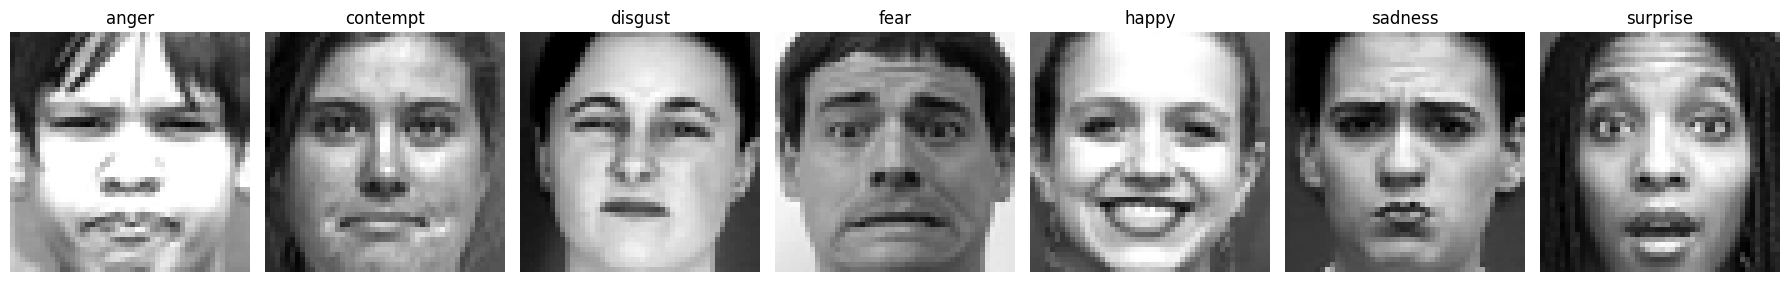

In [1]:
import os
import zipfile
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files


print("Upload your dataset:")
uploaded = files.upload()

#extract
zip_path = "archive.zip"
extract_path = "emotion_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

#set the extracted dataset path
dataset_path = extract_path

#we list the emotion classes from the folder
emotion_classes = sorted([
    d for d in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, d))
])

#count images and have one sample image per emotion
image_counts = {}
sample_images = {}

for emotion in emotion_classes:
    emotion_dir = os.path.join(dataset_path, emotion)
    files_in_emotion = [f for f in os.listdir(emotion_dir) if f.endswith('.png')]
    if files_in_emotion:
        image_counts[emotion] = len(files_in_emotion)
        sample_images[emotion] = os.path.join(emotion_dir, files_in_emotion[0])

#print the class distribution
print("Class Distribution:")
for emotion, count in image_counts.items():
    print(f"{emotion}: {count} images")

#show a sample image from each class
fig, axes = plt.subplots(1, len(sample_images), figsize=(18, 4))
for ax, (emotion, img_path) in zip(axes, sample_images.items()):
    img = Image.open(img_path).convert("L")
    ax.imshow(img, cmap='gray')
    ax.set_title(emotion)

    ax.axis('off')

plt.tight_layout()
plt.show()


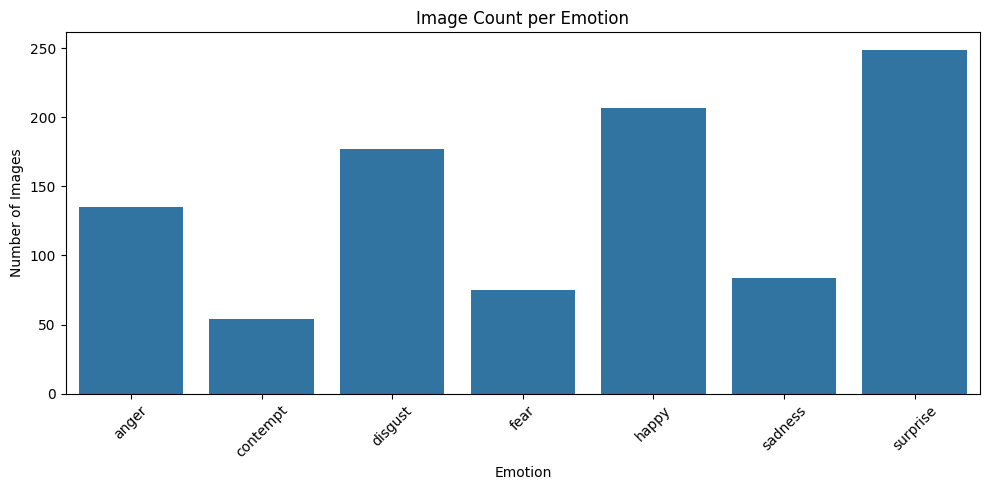


Most common image shapes:
(48, 48, 1): 350


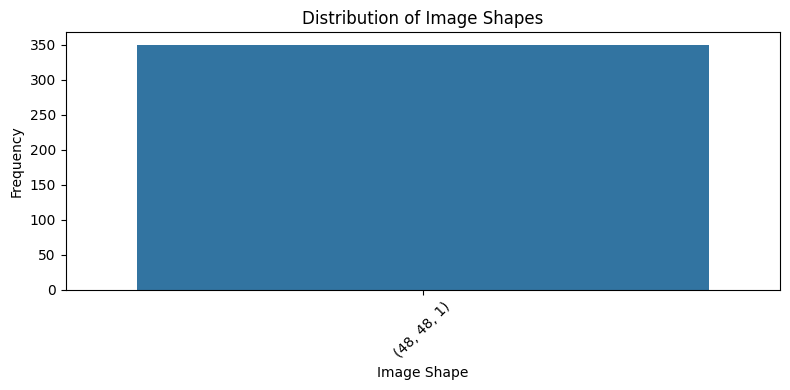

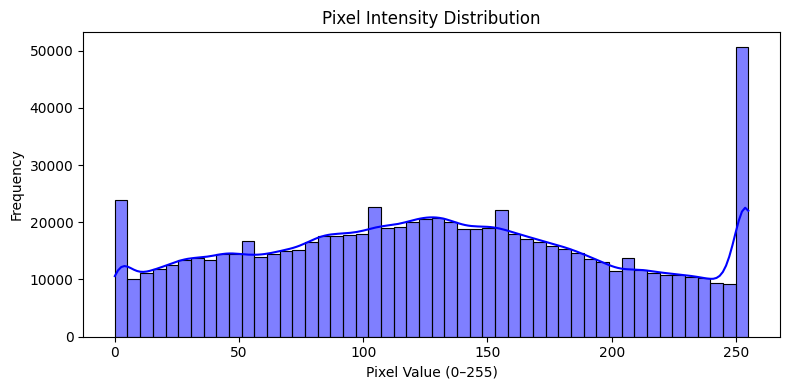

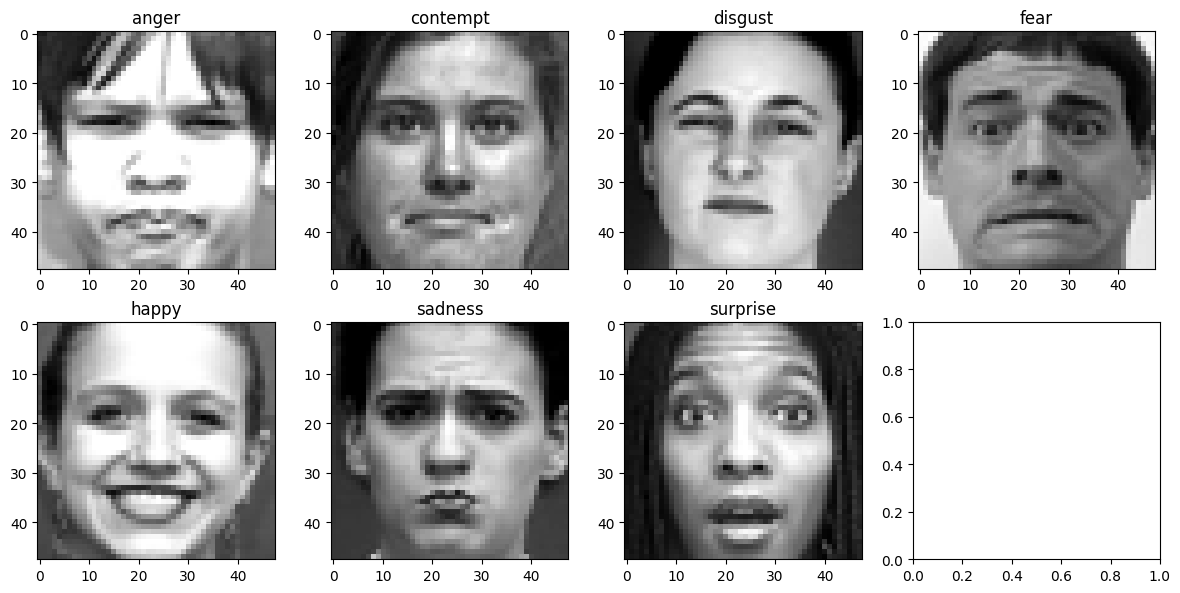

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array

#path to extracted dataset
dataset_path = "emotion_dataset"

#get the class folders
emotion_classes = sorted([
    d for d in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, d))
])


image_shapes = []
all_pixels = []

#we work up to 50 images per class for EDA
for emotion in emotion_classes:
    emotion_dir = os.path.join(dataset_path, emotion)
    image_files = [f for f in os.listdir(emotion_dir) if f.endswith('.png')]

    for img_name in image_files[:50]:
        img_path = os.path.join(emotion_dir, img_name)
        img = load_img(img_path, color_mode='grayscale')
        img_array = img_to_array(img)
        image_shapes.append(img_array.shape)
        all_pixels.extend(img_array.flatten())

#plot 1: class distribution
image_counts = {
    cls: len([f for f in os.listdir(os.path.join(dataset_path, cls)) if f.endswith('.png')])
    for cls in emotion_classes
}

plt.figure(figsize=(10, 5))
sns.barplot(x=list(image_counts.keys()), y=list(image_counts.values()))
plt.title("Image Count per Emotion")
plt.ylabel("Number of Images")
plt.xlabel("Emotion")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#plot 2: image shape distribution
shape_counts = Counter(image_shapes)
print("\nMost common image shapes:")
for shape, count in shape_counts.items():
    print(f"{shape}: {count}")

# plot 3: shape distribution
import pandas as pd
shape_df = pd.DataFrame(shape_counts.items(), columns=["Shape", "Count"])
shape_df["Shape"] = shape_df["Shape"].astype(str)

plt.figure(figsize=(8, 4))
sns.barplot(data=shape_df, x="Shape", y="Count")
plt.title("Distribution of Image Shapes")
plt.xlabel("Image Shape")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#plot 4: pixel intensity histogram
plt.figure(figsize=(8, 4))
sns.histplot(all_pixels, bins=50, kde=True, color='blue')
plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Value (0–255)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#plot 5: grid of sample images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()

for i, emotion in enumerate(emotion_classes[:8]):
    sample_dir = os.path.join(dataset_path, emotion)
    sample_files = [f for f in os.listdir(sample_dir) if f.endswith('.png')]
    sample_path = os.path.join(sample_dir, sample_files[0])
    sample_img = load_img(sample_path, color_mode='grayscale')
    axes[i].imshow(sample_img, cmap='gray')
    axes[i].set_title(emotion)

plt.tight_layout()
plt.show()



 Dataset loaded and split:
Training samples: 686
Validation samples: 98
Testing samples: 197
Class names: ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']

 Sample batch from train_ds:
 - Image batch shape: (32, 48, 48, 1)
 - Label batch shape: (32,)
 - Image pixel value range: 0.0 to 1.0
 - Image dtype: <dtype: 'float32'>
 - Image channels (should be 1): 1
 - Label values (encoded): [2 4 4 6 0]


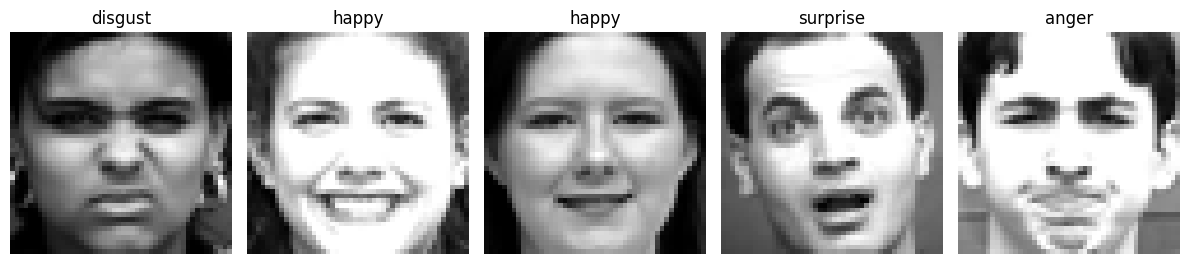

In [3]:
import os
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.data import Dataset
import matplotlib.pyplot as plt

#set parameters
dataset_path = "emotion_dataset"
img_height, img_width = 48, 48
batch_size = 32
seed = 123

#step 1: we load all images and labels into lists
image_paths = []
labels = []

class_names = sorted(os.listdir(dataset_path))
label_to_index = {name: i for i, name in enumerate(class_names)}

for label in class_names:
    class_dir = os.path.join(dataset_path, label)
    for fname in os.listdir(class_dir):
        if fname.endswith('.png'):
            image_paths.append(os.path.join(class_dir, fname))
            labels.append(label_to_index[label])


#step 2: split into train (70%), val (10%), test (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    image_paths, labels, test_size=0.2, random_state=seed, stratify=labels)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.125, random_state=seed, stratify=y_temp)
####### 0.125 of 80% = 10%


#step 3: define a function to load, resize, and normalize images
def process_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_png(img, channels=1)
    img = tf.image.resize(img, [img_height, img_width])
    img = tf.cast(img, tf.float32) / 255.0  #normalize to [0, 1]
    return img, label


#step 4: we create TensorFlow Datasets
def create_dataset(paths, labels):
    path_ds = tf.data.Dataset.from_tensor_slices(paths)
    label_ds = tf.data.Dataset.from_tensor_slices(labels)
    ds = tf.data.Dataset.zip((path_ds, label_ds))
    ds = ds.map(process_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = create_dataset(X_train, y_train)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)


#summary of the splits
print("\n Dataset loaded and split:")
print(f"Training samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")
print(f"Testing samples: {len(X_test)}")
print(f"Class names: {class_names}")


#step 5: verify preprocessing (shape, pixel range, grayscale, labels)
for images, labels in train_ds.take(1):
    print("\n Sample batch from train_ds:")
    print(" - Image batch shape:", images.shape)
    print(" - Label batch shape:", labels.shape)
    print(" - Image pixel value range:", tf.reduce_min(images).numpy(), "to", tf.reduce_max(images).numpy())
    print(" - Image dtype:", images.dtype)
    print(" - Image channels (should be 1):", images.shape[-1])
    print(" - Label values (encoded):", labels.numpy()[:5])


    #show 5 sample images with labels
    plt.figure(figsize=(12, 3))
    for i in range(5):
        ax = plt.subplot(1, 5, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap="gray")
        class_name = class_names[labels[i].numpy()]
        plt.title(class_name)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


Found 981 files belonging to 7 classes.
Using 785 files for training.
Found 981 files belonging to 7 classes.
Using 196 files for validation.


/usr/local/lib/python3.11/dist-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,847 (1.36 MB)

 Trainable params: 355,847 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - accuracy: 0.2014 - loss: 1.8859 - val_accuracy: 0.2292 - val_loss: 1.7929
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - accuracy: 0.2279 - loss: 1.8229 - val_accuracy: 0.2812 - val_loss: 1.7452
Epoch 3/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - accuracy: 0.3473 - loss: 1.7502 - val_accuracy: 0.5625 - val_loss: 1.5665
Epoch 4/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 180ms/step - accuracy: 0.5179 - loss: 1.4421 - val_accuracy: 0.6771 - val_loss: 1.0530
Epoch 5/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - accuracy: 0.6062 - loss: 1.1442 - val_accuracy: 0.6771 - val_loss: 0.7983
Epoch 6/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step - accuracy: 0.6544 - loss: 0.9208 - val_accuracy: 0.7708 - val_loss: 0.5914
Epoch 7/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - accuracy: 0.7022 - loss: 0.7520 - val_accuracy: 0.7917 - val_loss: 0.5566
Epoch 8/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 150ms/step - accuracy: 0.7287 - loss: 0.6895 - val_accuracy: 0.8438

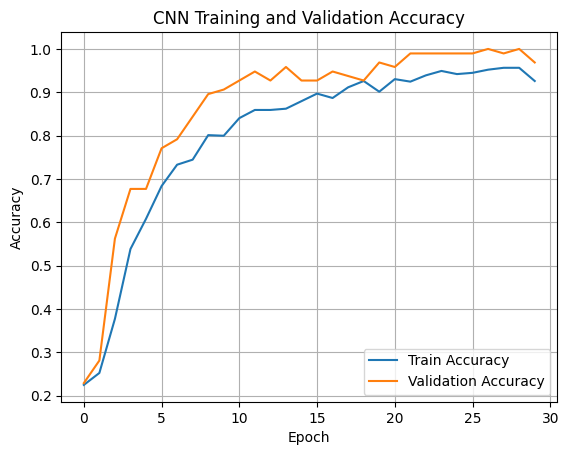

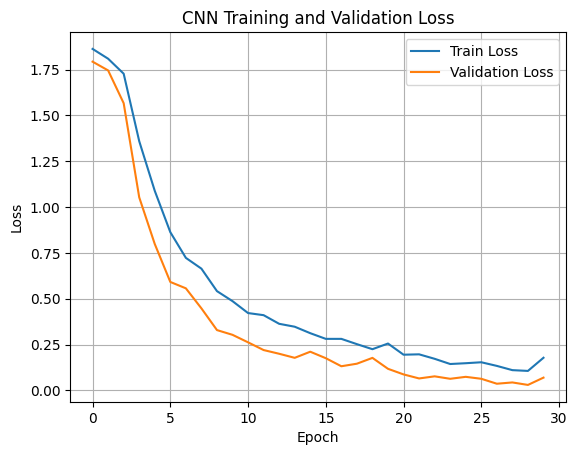


 Final Training Accuracy: 0.9260
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9650 - loss: 0.1063
 Test Accuracy: 0.97


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


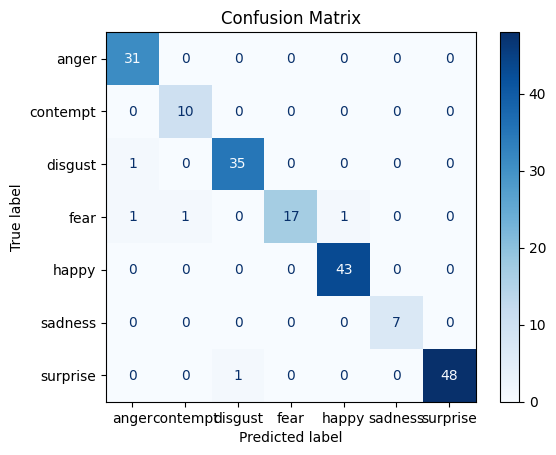


 Classification Report:
              precision    recall  f1-score   support

       anger       0.94      1.00      0.97        31
    contempt       0.91      1.00      0.95        10
     disgust       0.97      0.97      0.97        36
        fear       1.00      0.85      0.92        20
       happy       0.98      1.00      0.99        43
     sadness       1.00      1.00      1.00         7
    surprise       1.00      0.98      0.99        49

    accuracy                           0.97       196
   macro avg       0.97      0.97      0.97       196
weighted avg       0.98      0.97      0.97       196



In [13]:
#mohanad - cnn

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os
from tensorflow.keras.utils import plot_model
from IPython.display import Image
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report


#step 1: set dataset path and extract class names
dataset_path = "emotion_dataset"
class_names = sorted(os.listdir(dataset_path))
num_classes = len(class_names)


#step 2: create image datasets (train, val, test)
# the split: 70% train, 20% test, 10% validation
image_size = (48, 48)
batch_size = 32
seed = 123

#first: split into train + temp (80%) and test (20%)
train_val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=seed,
    image_size=image_size,
    batch_size=batch_size,
    color_mode='grayscale'
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    image_size=image_size,
    batch_size=batch_size,
    color_mode='grayscale'
)

#second: split train_val into train (87.5% of 80%=≈ 70%) and val (12.5% of 80% = 10%)
val_size = int(0.125 * len(train_val_ds))
val_ds = train_val_ds.take(val_size)
train_ds = train_val_ds.skip(val_size)


#step 3: inhance performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)


#step 4: build the CNN model
model = tf.keras.models.Sequential([
    tf.keras.layers.Rescaling(1./255, input_shape=(48, 48, 1)),  # we normalize pixel values

    #Convolution Blocks
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(num_classes, activation='softmax')  #output layer
])


#step 5: Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#step 6: Model Summary
model.summary()
plot_model(model, to_file="cnn_model.png", show_shapes=False, show_layer_names=False, dpi=40, rankdir="LR")
display(Image(filename="cnn_model.png"))




# ✅ Step 7: Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30
)

# 📈 Step 8: Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN Training and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CNN Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()


#step 9: Final training accuracy
final_train_acc = history.history['accuracy'][-1]
print(f"\n Final Training Accuracy: {final_train_acc:.4f}")

#step 10: Evaluate on test dataset
test_loss, test_accuracy = model.evaluate(test_ds)
print(f" Test Accuracy: {test_accuracy:.2f}")


#Step 11: Confusion Matrix and Classification Report

#get predictions
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

#xxtract true labels
y_true = np.concatenate([label.numpy() for _, label in test_ds], axis=0)

#plot the confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

#classification report
print("\n Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))



 Training Accuracy: 92.71%
 Test Accuracy: 57.87%

 Classification Report:
              precision    recall  f1-score   support

       anger       0.38      0.70      0.49        27
    contempt       0.73      1.00      0.85        11
     disgust       0.52      0.43      0.47        35
        fear       0.42      0.33      0.37        15
       happy       0.71      0.40      0.52        42
     sadness       0.53      0.53      0.53        17
    surprise       0.76      0.76      0.76        50

    accuracy                           0.58       197
   macro avg       0.58      0.59      0.57       197
weighted avg       0.61      0.58      0.57       197



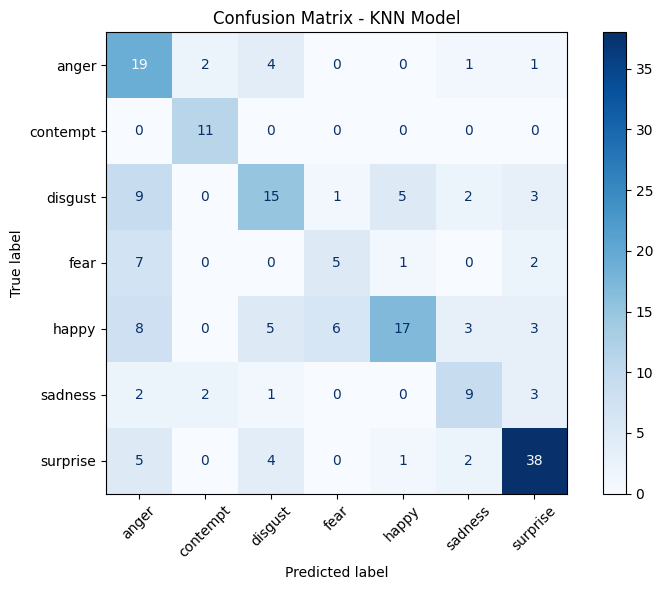

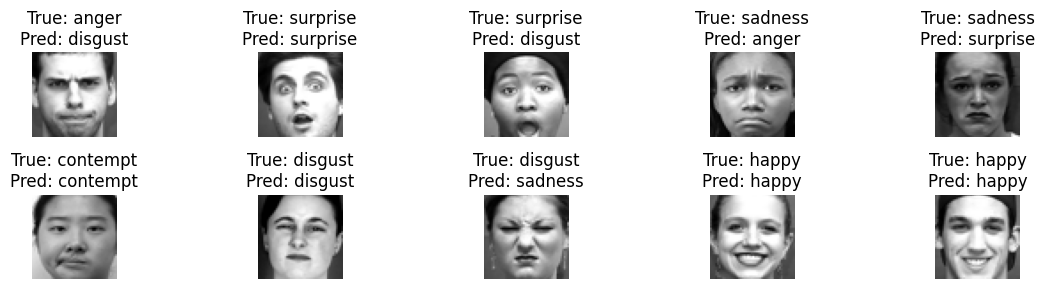

In [6]:
#jana - KNN
import os
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import random

#constants
dataset_path = "emotion_dataset"
img_height, img_width = 48, 48
seed = 123

#1.  we load images into NumPy arrays
X_all = []
y_all = []
class_names = sorted(os.listdir(dataset_path))
label_to_index = {name: i for i, name in enumerate(class_names)}

for label in class_names:
    class_dir = os.path.join(dataset_path, label)
    for fname in os.listdir(class_dir):
        if fname.endswith(".png"):
            img_path = os.path.join(class_dir, fname)
            img = Image.open(img_path).convert("L")
            img = img.resize((img_width, img_height))
            img_array = np.array(img) / 255.0  # Normalize to [0, 1]
            X_all.append(img_array.flatten())  # Flatten to 1D
            y_all.append(label_to_index[label])

X_all = np.array(X_all)
y_all = np.array(y_all)


#2. split (train 70%, val 10%, test 20%)
X_temp, X_test, y_temp, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=seed, stratify=y_all)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.125, random_state=seed, stratify=y_temp)
# 0.125 of 80% = 10%


# 3. normalize features
scaler = StandardScaler()
X_train_np = scaler.fit_transform(X_train)
X_test_np = scaler.transform(X_test)

#4. train KNN model
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_np, y_train)

#5. predict
y_pred_test = knn.predict(X_test_np)
y_pred_train = knn.predict(X_train_np)  # <-- Added line for training predictions

#6. accuracy
train_acc = accuracy_score(y_train, y_pred_train)  # <-- Added line for training accuracy
print(f"\n Training Accuracy: {train_acc * 100:.2f}%")
test_acc = accuracy_score(y_test, y_pred_test)
print(f" Test Accuracy: {test_acc * 100:.2f}%")

#7. classification report
print("\n Classification Report:")
print(classification_report(y_test, y_pred_test, target_names=class_names))

#8. show 10 random test predictions
sample_indices = random.sample(range(len(X_test_np)), 10)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt



#compute confusion matrix
cm = confusion_matrix(y_test, y_pred_test)

#display the confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title("Confusion Matrix - KNN Model")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 3))
for i, idx in enumerate(sample_indices):
    img = X_test[idx].reshape(img_height, img_width)
    true_label = class_names[y_test[idx]]
    pred_label = class_names[y_pred_test[idx]]

    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(f"True: {true_label}\nPred: {pred_label}")
    plt.axis("off")

plt.tight_layout()
plt.show()



<ipython-input-7-e989e2edf739>:76: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 151ms/step - accuracy: 0.1223 - loss: 3.2057 - val_accuracy: 0.3163 - val_loss: 1.8719
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - accuracy: 0.3627 - loss: 1.8971 - val_accuracy: 0.3980 - val_loss: 1.4819
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.4521 - loss: 1.5326 - val_accuracy: 0.4286 - val_loss: 1.3009
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.4985 - loss: 1.3684 - val_accuracy: 0.5204 - val_loss: 1.1918
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 112ms/step - accuracy: 0.5581 - loss: 1.2208 - val_accuracy: 0.5306 - val_loss: 1.1276
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.5774 - loss: 1.1039 - val_accuracy: 0.6020 - val_loss: 1.0600
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.6440 - loss: 1.0153 - val_accuracy: 0.6429 - val_loss: 1.0118
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accurac

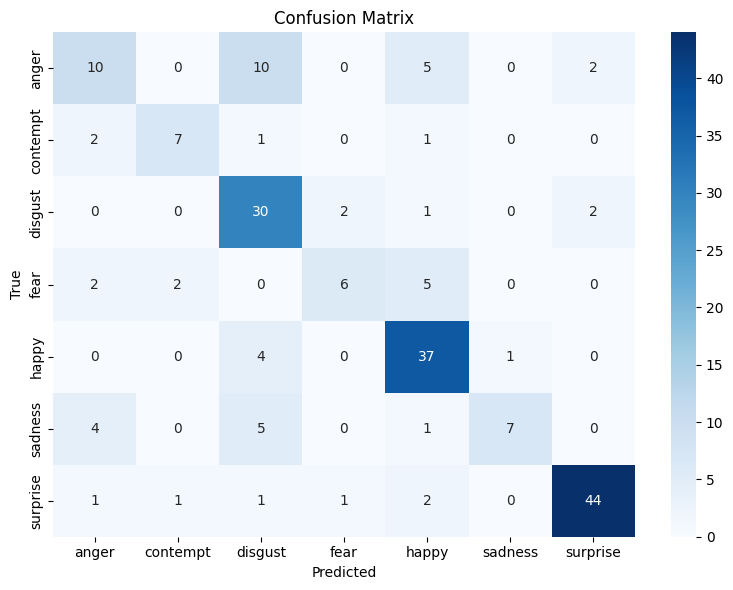

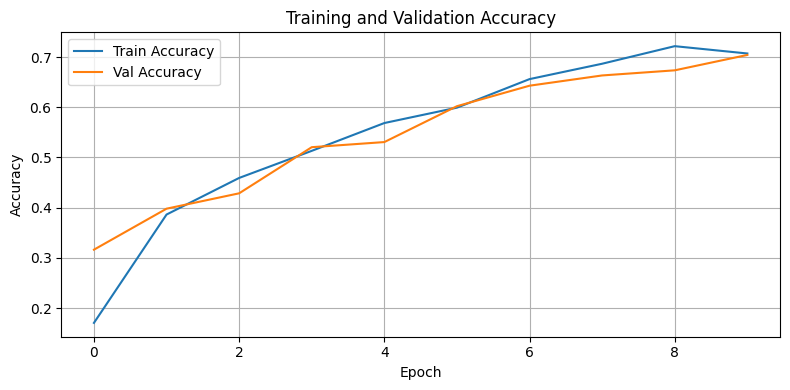

In [7]:
# jana - MobileNetV2
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns

#constants
dataset_path = "emotion_dataset"
img_height, img_width = 48, 48
batch_size = 32
seed = 123

#load image paths and labels
image_paths = []
labels = []
class_names = sorted(os.listdir(dataset_path))
label_to_index = {name: i for i, name in enumerate(class_names)}

for label in class_names:
    class_dir = os.path.join(dataset_path, label)
    for fname in os.listdir(class_dir):
        if fname.endswith('.png'):
            image_paths.append(os.path.join(class_dir, fname))
            labels.append(label_to_index[label])



#split dataset
X_temp, X_test, y_temp, y_test = train_test_split(
    image_paths, labels, test_size=0.2, random_state=seed, stratify=labels)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.125, random_state=seed, stratify=y_temp)
# 0.125 of 80% = 10%


#convert image paths to strings
X_train = [str(p) for p in X_train]
X_val = [str(p) for p in X_val]
X_test = [str(p) for p in X_test]


#convert grayscale to RGB
def preprocess_rgb(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_png(img, channels=1)
    img = tf.image.resize(img, [img_height, img_width])
    img = tf.image.grayscale_to_rgb(img)
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def create_rgb_dataset(paths, labels):
    path_ds = tf.data.Dataset.from_tensor_slices(paths)
    label_ds = tf.data.Dataset.from_tensor_slices(labels)
    ds = tf.data.Dataset.zip((path_ds, label_ds))
    ds = ds.map(preprocess_rgb, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds_rgb = create_rgb_dataset(X_train, y_train)
val_ds_rgb = create_rgb_dataset(X_val, y_val)
test_ds_rgb = create_rgb_dataset(X_test, y_test)



#build the model
IMG_SHAPE = (img_height, img_width, 3)
NUM_CLASSES = len(class_names)

base_model = MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.compile(optimizer=Adam(learning_rate=0.0005),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


#train model
history = model.fit(
    train_ds_rgb,
    validation_data=val_ds_rgb,
    epochs=10
)


#training & Test Accuracy
train_loss, train_acc = model.evaluate(train_ds_rgb, verbose=0)
print(f"\n Training Accuracy: {train_acc * 100:.2f}%")

test_loss, test_acc = model.evaluate(test_ds_rgb)
print(f" Test Accuracy: {test_acc * 100:.2f}%")


#predict on test set
y_pred = []
y_true = []

for images, labels in test_ds_rgb:
    preds = model.predict(images)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())



#classification report
print("\nc Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))


#confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()


#plot accuracy over epochs
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


 Flattening training & testing images...

 Training SVM...

 Training Accuracy: 1.0000
 Test Accuracy: 0.9949


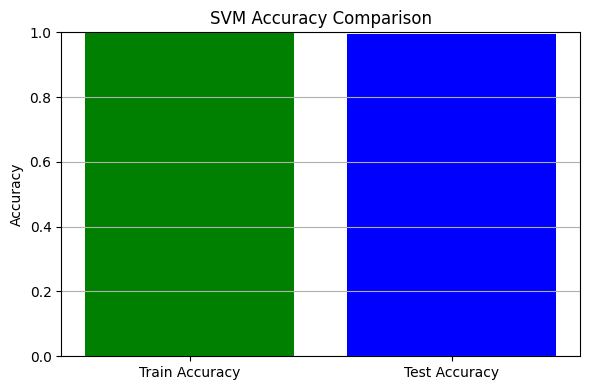


 Classification Report:
              precision    recall  f1-score   support

       anger       1.00      1.00      1.00        27
    contempt       1.00      1.00      1.00        11
     disgust       0.97      1.00      0.99        35
        fear       1.00      0.93      0.97        15
       happy       1.00      1.00      1.00        42
     sadness       1.00      1.00      1.00        17
    surprise       1.00      1.00      1.00        50

    accuracy                           0.99       197
   macro avg       1.00      0.99      0.99       197
weighted avg       1.00      0.99      0.99       197


 Macro F1-score: 0.9931
 Weighted F1-score: 0.9949


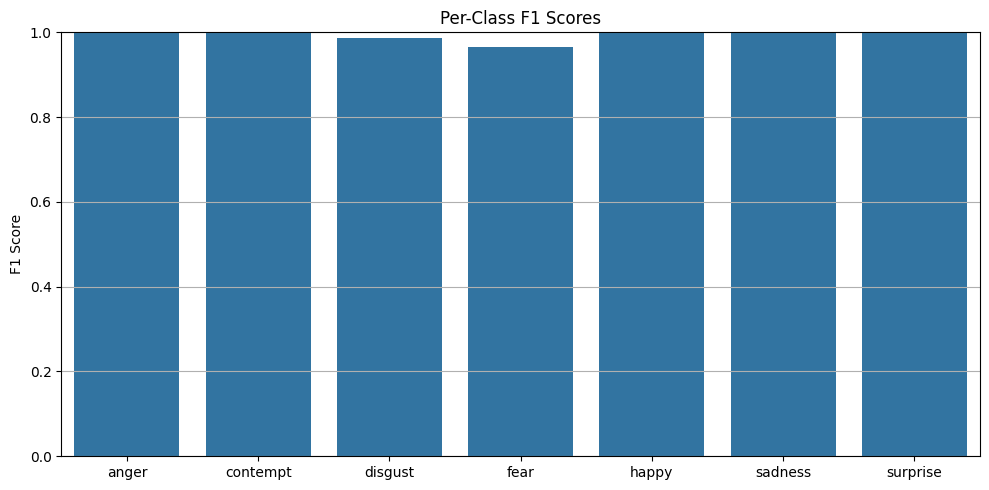

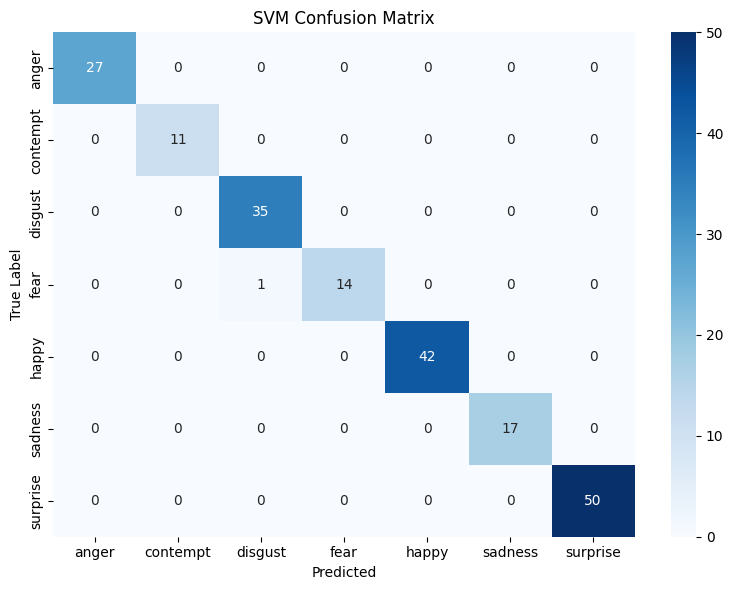

In [9]:
#Zeina - SVM
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.utils.multiclass import unique_labels
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np


#load and flatten images (grayscale, 48x48) for SVM
def load_and_flatten_images(image_paths):
    data = []
    for path in image_paths:
        img = load_img(path, color_mode='grayscale', target_size=(48, 48))
        img_array = img_to_array(img).flatten()
        data.append(img_array)
    return np.array(data)

print("\n Flattening training & testing images...")
X_train_flat = load_and_flatten_images(X_train)
X_test_flat = load_and_flatten_images(X_test)


#normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_flat)
X_test_scaled = scaler.transform(X_test_flat)


#train SVM model
print("\n Training SVM...")
svm_model = SVC(kernel='linear', C=1.0)
svm_model.fit(X_train_scaled, y_train)


#Training accuracy
y_train_pred = svm_model.predict(X_train_scaled)
train_acc = accuracy_score(y_train, y_train_pred)
print(f"\n Training Accuracy: {train_acc:.4f}")

#evaluate on test data
y_pred = svm_model.predict(X_test_scaled)
test_acc = accuracy_score(y_test, y_pred)
print(f" Test Accuracy: {test_acc:.4f}")



#bar Plot of Accuracies
plt.figure(figsize=(6, 4))
plt.bar(['Train Accuracy', 'Test Accuracy'], [train_acc, test_acc], color=['green', 'blue'])
plt.ylim(0, 1)
plt.title('SVM Accuracy Comparison')
plt.ylabel('Accuracy')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


#classification Report (handles missing classes in test set)
present_labels = unique_labels(y_test, y_pred)
present_class_names = [class_names[i] for i in present_labels]

print("\n Classification Report:")
report = classification_report(y_test, y_pred, target_names=present_class_names, output_dict=True)
print(classification_report(y_test, y_pred, target_names=present_class_names))


#print macro and weighted F1-scores
macro_f1 = report["macro avg"]["f1-score"]
weighted_f1 = report["weighted avg"]["f1-score"]
print(f"\n Macro F1-score: {macro_f1:.4f}")
print(f" Weighted F1-score: {weighted_f1:.4f}")




#F1 Score Bar Chart per class
f1_scores = [report[label]["f1-score"] for label in present_class_names]
plt.figure(figsize=(10, 5))
sns.barplot(x=present_class_names, y=f1_scores)
plt.title("Per-Class F1 Scores")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

#confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=present_class_names, yticklabels=present_class_names, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()

Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 116ms/step - accuracy: 0.1672 - loss: 28.4972 - val_accuracy: 0.3542 - val_loss: 1.8120
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.2433 - loss: 1.9231 - val_accuracy: 0.2396 - val_loss: 1.9380
Epoch 3/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - accuracy: 0.2603 - loss: 1.9365 - val_accuracy: 0.2396 - val_loss: 1.9313
Epoch 4/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - accuracy: 0.2345 - loss: 1.9294 - val_accuracy: 0.2396 - val_loss: 1.9249


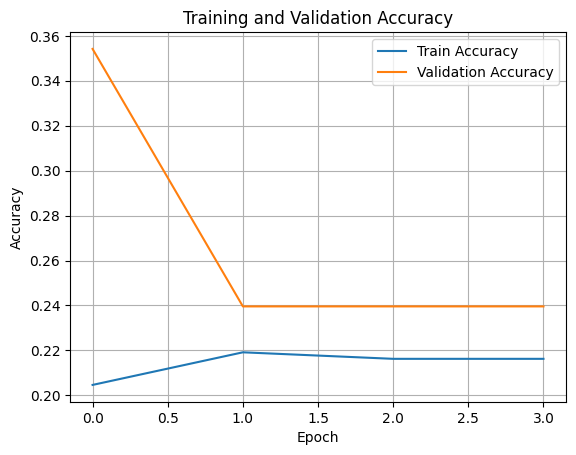


 Final Training Accuracy: 0.2163
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3882 - loss: 1.8108

 Test Accuracy: 0.3776


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step


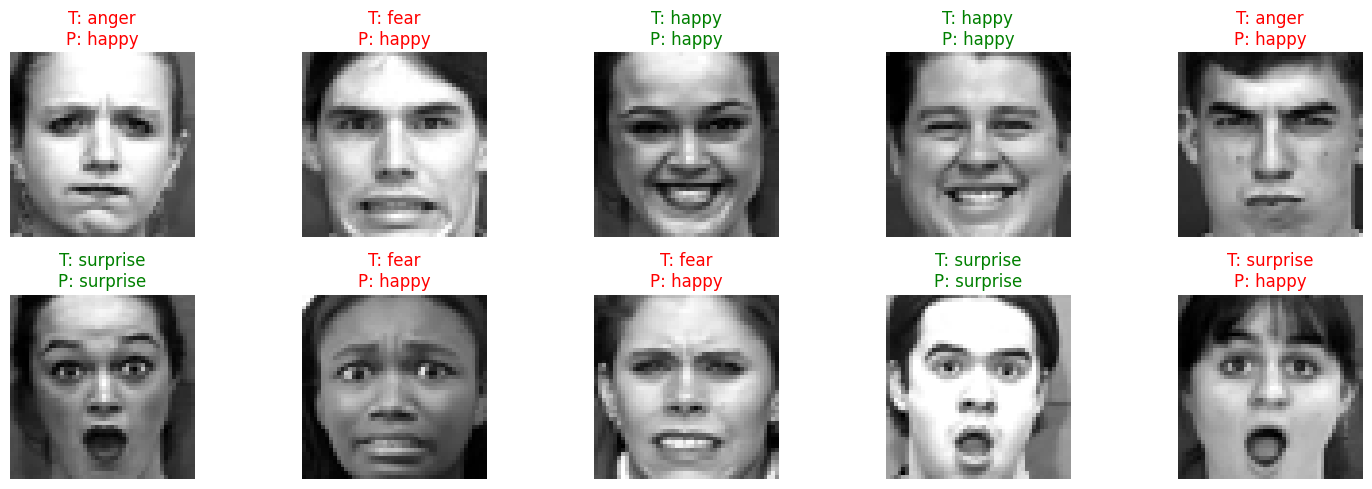

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
 Accuracy Score: 0.37755102040816324
 Classification Report:
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        31
    contempt       0.00      0.00      0.00        10
     disgust       0.00      0.00      0.00        36
        fear       0.00      0.00      0.00        20
       happy       0.25      0.79      0.38        43
     sadness       0.00      0.00      0.00         7
    surprise       0.68      0.82      0.74        49

    accuracy                           0.38       196
   macro avg       0.13      0.23      0.16       196
weighted avg       0.23      0.38      0.27       196



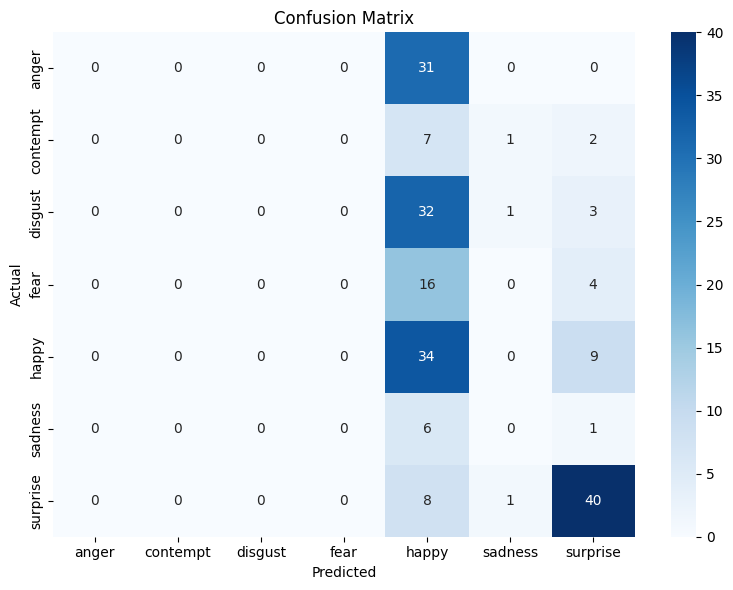

In [12]:
# sarah - mlp
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

# Class labels
class_names = ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']

# Define the CNN model
cnn_model = models.Sequential([
    layers.Input(shape=(48, 48, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

# Compile the model
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Early stopping callback
early_stop = EarlyStopping(
    patience=3,
    restore_best_weights=True
)

# Train the model
history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stop]
)

# Plot training & validation accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.grid(True)
plt.show()

#Print final training accuracy
final_train_acc = history.history['accuracy'][-1]
print(f"\n Final Training Accuracy: {final_train_acc:.4f}")

#Evaluate on the test set
test_loss, test_acc = cnn_model.evaluate(test_ds)
print(f"\n Test Accuracy: {test_acc:.4f}")

# Visualize predictions on 1 batch
for images, labels in test_ds.take(1):
    preds = cnn_model.predict(images)
    pred_labels = np.argmax(preds, axis=1)

    plt.figure(figsize=(15, 5))
    for i in range(min(10, images.shape[0])):
        ax = plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        true_label = class_names[labels[i].numpy()]
        predicted_label = class_names[pred_labels[i]]
        color = 'green' if true_label == predicted_label else 'red'
        plt.title(f"T: {true_label}\nP: {predicted_label}", color=color)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

#Evaluate full test set
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = cnn_model.predict(images)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

#Accuracy & classification report
print(" Accuracy Score:", accuracy_score(y_true, y_pred))
print(" Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

#Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()
